In [ ]:
import pandas as pd

df = pd.read_csv("/content/sample_data/job_mkACVtLzQk5kBHU4Vyw1H95NouA1.csv")

In [ ]:
print(df.shape)
print(df.columns.tolist())

(20000, 8)
['reviewid', 'playerid', 'gameid', 'review', 'helpful', 'funny', 'awards', 'posted']


In [ ]:
df["review"].sample(100).tolist()

['the year is 1982one man one missionnothing can or will stop himhis namejorgi(out now on steam)',
 'Keine Gute Steuerung und Dualshock 3 funktioniert nicht.Server Down Nerven DownHätte ich es nur auf ps3 gekauft wartet mit dem Kauf',
 'Extrem Gutes Spiel :D, ist zwar noch nicht fertig aber ich freue mich schon auf das Fertige Spiel :)',
 'It is a really amazing game. It has the features of reality, war, and realism. my opinnion is that it is better then any other FPS game and deserves a GOTY.',
 'COOL GAME MUCH FRIENDS GOTZ ITZ',
 '⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀♫ Slender  ♫⠀⠀⠀⠀───────⚪───────────────────────────────────⠀▐▐ ⠀►▏ ⠀⠀──○─\u2004🔊 ⠀₁:₂₅ / ₃:₅₀ ⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀ᴴᴰ⚙ ❐ ⊏⊐ https://www.youtube.com/watch?v=-wt0PuBHCW8',
 'Отличная игруха! У меня говно на жопе высыхает от таких засиживаний. Не оторваться!',
 '只是冲着以前玩过的回忆买的，算是当年很不错的游戏吧，比较独特的太空题材。就现在来看，这个游戏仍然有很多现在的游戏无法媲美的优点。',
 "Cars crash, birds fly, and brother, I crash flying cars. Brilliant game, if you're a fan of cars, racing, cras

In [ ]:
def classify_complaint(text):

    text = str(text).lower()

    if any(x in text for x in ["bug","glitch","broken"]):
        return "Bug"

    if any(x in text for x in ["crash","crashing"]):
        return "Crash"

    if any(x in text for x in ["update","patch"]):
        return "Update"

    if any(x in text for x in ["price","expensive","cost"]):
        return "Price"

    if any(x in text for x in ["server","connection"]):
        return "Server"

    if any(x in text for x in ["lag","latency"]):
        return "Lag"

    if any(x in text for x in ["dlc","expansion"]):
        return "DLC"

    return "Other"

In [ ]:
df["complaint_type"] = df["review"].apply(classify_complaint)

In [ ]:
!pip install lingua-language-detector -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.3/170.3 MB 7.0 MB/s eta 0:00:00


In [ ]:
from lingua import Language, LanguageDetectorBuilder

detector = LanguageDetectorBuilder.from_languages(
    Language.ENGLISH
).build()

In [ ]:
def is_english(text):
    try:
        lang = detector.detect_language_of(str(text))
        return lang == Language.ENGLISH
    except:
        return False

In [ ]:
df["is_english"] = df["review"].apply(is_english)

In [ ]:
df_en = df[df["is_english"] == True].copy()

print(df_en.shape)

(12158, 10)


In [ ]:
def classify_complaint(text):

    text = str(text).lower()

    if any(x in text for x in ["bug","glitch","broken"]):
        return "Bug"

    if any(x in text for x in ["crash","crashing"]):
        return "Crash"

    if any(x in text for x in ["update","patch"]):
        return "Update"

    if any(x in text for x in ["price","expensive","cost"]):
        return "Price"

    if any(x in text for x in ["server","connection"]):
        return "Server"

    if any(x in text for x in ["lag","latency"]):
        return "Lag"

    if any(x in text for x in ["dlc","expansion"]):
        return "DLC"

    if any(x in text for x in ["hack","hacker","cheat","cheater"]):
        return "Cheater"

    return "Other"

In [ ]:
df_en["complaint_type"] = df_en["review"].apply(classify_complaint)

In [ ]:
df_en["complaint_type"].value_counts()

,count
complaint_type,
Other,10215
Bug,516
Price,358
Update,276
Cheater,201
DLC,194
Server,172
Crash,118
Lag,108


In [ ]:
def classify_complaint(text):

    text = str(text).lower()

    if any(x in text for x in [
        "bug","bugs","buggy",
        "glitch","glitches",
        "broken",
        "issue","issues",
        "problem","problems",
        "not working",
        "doesn't work",
        "unplayable",
        "fix this"
    ]):
        return "Bug"

    if any(x in text for x in [
        "crash",
        "crashes",
        "crashing",
        "crashed",
        "freeze",
        "freezing",
        "frozen"
    ]):
        return "Crash"

    if any(x in text for x in [
        "update",
        "patch",
        "patched",
        "after update",
        "new update",
        "latest update"
    ]):
        return "Update"

    if any(x in text for x in [
        "price",
        "expensive",
        "too expensive",
        "cost",
        "overpriced",
        "not worth"
    ]):
        return "Price"

    if any(x in text for x in [
        "server",
        "servers",
        "connection",
        "disconnect",
        "disconnected",
        "matchmaking"
    ]):
        return "Server"

    if any(x in text for x in [
        "lag",
        "laggy",
        "latency",
        "stutter",
        "fps drop",
        "performance"
    ]):
        return "Lag"

    if any(x in text for x in [
        "dlc",
        "expansion",
        "expansions",
        "paywall"
    ]):
        return "DLC"

    if any(x in text for x in [
        "hack",
        "hacker",
        "hackers",
        "cheat",
        "cheater",
        "cheaters"
    ]):
        return "Cheater"

    return "Other"

In [ ]:
df_en["complaint_type"] = df_en["review"].apply(classify_complaint)

df_en["complaint_type"].value_counts()

,count
complaint_type,
Other,9874
Bug,949
Price,353
Update,234
Cheater,182
DLC,177
Server,172
Lag,109
Crash,108


In [ ]:
df_en[df_en["complaint_type"]=="Other"]["review"].sample(100)

,review
19258,Just defeated the hand of the king. Amazing ga...
9938,"Best game ever, play it more often than tf2 an..."
17027,"Amazing gameplay very addictive , orignal hero..."
19519,One of the dumbest endings in the history of v...
9418,"Ok, first of all I'm a huge fan of the Deus Ex..."
...,...
14921,Foarte smecher jocul
13545,GREAT Puzzle Game.There are many theories abou...
2613,What is the objective of this game? Can anyone...
6688,Really great game! One of most accurate footba...


In [ ]:
df_en["complaint_type"].value_counts(normalize=True) * 100

,proportion
complaint_type,
Other,81.214015
Bug,7.805560
Price,2.903438
Update,1.924659
Cheater,1.496957
DLC,1.455832
Server,1.414706
Lag,0.896529
Crash,0.888304


<Axes: xlabel='complaint_type'>

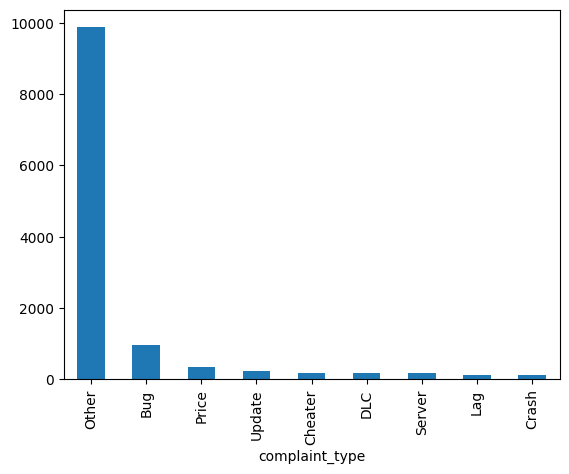

In [ ]:
df_en["complaint_type"].value_counts().plot.bar()

In [ ]:
df_en.to_csv("reviews_enriched.csv", index=False)

In [ ]:
from google.colab import files

files.download("reviews_enriched.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<Axes: xlabel='complaint_type'>

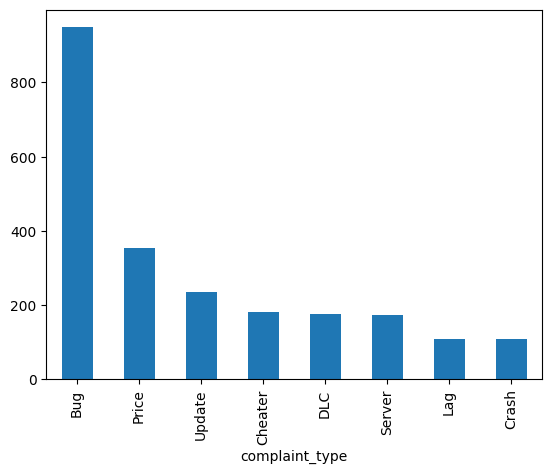

In [ ]:
df_en[df_en["complaint_type"]!="Other"]["complaint_type"].value_counts().plot.bar()

In [ ]:
df_en.to_csv("reviews_enriched.csv", index=False)

In [ ]:
from google.colab import files

files.download("reviews_enriched.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
df_ml = df_en[df_en["complaint_type"] != "Other"].copy()

In [ ]:
df_ml["complaint_type"].value_counts()

,count
complaint_type,
Bug,949
Price,353
Update,234
Cheater,182
DLC,177
Server,172
Lag,109
Crash,108


In [ ]:
X = df_ml["review"]

y = df_ml["complaint_type"]

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=5000,
    stop_words="english"
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=3000
)

model.fit(X_train_tfidf, y_train)

LogisticRegression(max_iter=3000)

In [ ]:
y_pred = model.predict(X_test_tfidf)

In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.6148796498905909


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

         Bug       0.53      0.96      0.68       190
     Cheater       0.85      0.31      0.45        36
       Crash       0.80      0.18      0.30        22
         DLC       1.00      0.37      0.54        35
         Lag       0.00      0.00      0.00        22
       Price       0.85      0.56      0.68        71
      Server       1.00      0.38      0.55        34
      Update       0.90      0.38      0.54        47

    accuracy                           0.61       457
   macro avg       0.74      0.39      0.47       457
weighted avg       0.70      0.61      0.58       457



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
new_review = [
    "The servers keep disconnecting every match"
]

pred = model.predict(
    tfidf.transform(new_review)
)

print(pred)

['Server']


In [ ]:
from sklearn.metrics import accuracy_score

y_pred = model.predict(X_test_tfidf)

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy*100,2), "%")

Accuracy: 61.49 %


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

         Bug       0.53      0.96      0.68       190
     Cheater       0.85      0.31      0.45        36
       Crash       0.80      0.18      0.30        22
         DLC       1.00      0.37      0.54        35
         Lag       0.00      0.00      0.00        22
       Price       0.85      0.56      0.68        71
      Server       1.00      0.38      0.55        34
      Update       0.90      0.38      0.54        47

    accuracy                           0.61       457
   macro avg       0.74      0.39      0.47       457
weighted avg       0.70      0.61      0.58       457



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[182   2   1   0   0   3   0   2]
 [ 24  11   0   0   0   1   0   0]
 [ 18   0   4   0   0   0   0   0]
 [ 20   0   0  13   0   2   0   0]
 [ 22   0   0   0   0   0   0   0]
 [ 31   0   0   0   0  40   0   0]
 [ 21   0   0   0   0   0  13   0]
 [ 28   0   0   0   0   1   0  18]]
